# 02 · Model Bayesian stok beras dari panel gabungan

Notebook ini **hanya membaca `data_gabungan/`** (hasil `01_gabung_data.ipynb`), lalu menjalankan model
state-space Bayesian stok beras per provinsi (PyMC + nutpie) dan menyimpan ringkasan ke `hasil/`.

Persamaan keadaan (provinsi p, bulan t; t = 0 = akhir Juni 2022):

```
X[p,t] = X[p,t-1] + (1-s)·P[p,t] + I[t]·w[p] - (1+ν_y)·C[p,t] + θ[p]·D[p]·g[t] - K[p]·m[p,t] + e[p,t]
```

Pengamatan: survei stok (SCBN 2022, SSBAT 2022–2023) dengan bias per sumber, stok BULOG (publik + INATRADE 00372),
indeks stok pedagang INATRADE per pulau (Student-t), perubahan harga penggilingan 12 bulan. Kendala lunak: stok
total provinsi ≥ 0, stok swasta per pulau ≥ 0.

**Waktu jalan:** di Colab (2 inti CPU) sekitar 20–40 menit untuk 4 rantai × 1.000 draw. Untuk mencoba cepat,
turunkan `DRAWS`/`TUNE` (hasil kurang stabil). Dengan setelan bawaan dan data yang sama, hasilnya sama dengan
skenario dasar di dokumen dan dashboard (stok nasional akhir Sep 2026 ±14,2 juta ton).

In [1]:
import sys, subprocess
if 'google.colab' in sys.modules:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pymc>=5.20', 'nutpie'], check=True)

In [2]:
import os, sys, json, re, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DI_COLAB = 'google.colab' in sys.modules
if DI_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/beras_colab'   # <- ganti bila folder diunggah ke tempat lain
else:
    BASE = os.path.abspath('.')                    # dijalankan dari dalam folder beras_colab
RAW = os.path.join(BASE, 'data_raw')
GAB = os.path.join(BASE, 'data_gabungan')
assert os.path.isdir(RAW), f'folder data_raw tidak ditemukan di {BASE}'
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

BARIS = 'semua'          # panel yang dipakai: 'semua', 'nonpaw', 'paw' (harus sudah dibuat di notebook 01)
DRAWS, TUNE, CHAINS, SEED = 1000, 2000, 4, 2026
HOLDOUT = None           # mis. '2022-12' untuk menyembunyikan survei Des 2022 (uji validasi)
POSITIF = 'pulau'        # tingkat kendala stok swasta >= 0: 'pulau' (dasar), 'provinsi', 'nasional'
TANPA = ()               # mis. ('inatrade', 'bulog_inatrade') untuk varian tanpa INATRADE
AWAL, AKHIR = '2022-07', '2026-09'
SUFFIX = '' if BARIS == 'semua' else '_' + BARIS
HASIL = os.path.join(BASE, 'hasil'); os.makedirs(HASIL, exist_ok=True)

In [3]:
# Wilayah: 38 provinsi, 6 kelompok pulau
PULAU = {'Sumatera': ['ACEH', 'SUMATERA UTARA', 'SUMATERA BARAT', 'RIAU', 'JAMBI', 'SUMATERA SELATAN', 'BENGKULU', 'LAMPUNG', 'KEPULAUAN BANGKA BELITUNG', 'KEPULAUAN RIAU'], 'Jawa': ['DKI JAKARTA', 'JAWA BARAT', 'JAWA TENGAH', 'DAERAH ISTIMEWA YOGYAKARTA', 'JAWA TIMUR', 'BANTEN'], 'Bali & Nusa Tenggara': ['BALI', 'NUSA TENGGARA BARAT', 'NUSA TENGGARA TIMUR'], 'Kalimantan': ['KALIMANTAN BARAT', 'KALIMANTAN TENGAH', 'KALIMANTAN SELATAN', 'KALIMANTAN TIMUR', 'KALIMANTAN UTARA'], 'Sulawesi': ['SULAWESI UTARA', 'SULAWESI TENGAH', 'SULAWESI SELATAN', 'SULAWESI TENGGARA', 'GORONTALO', 'SULAWESI BARAT'], 'Maluku & Papua': ['MALUKU', 'MALUKU UTARA', 'PAPUA BARAT', 'PAPUA BARAT DAYA', 'PAPUA', 'PAPUA SELATAN', 'PAPUA TENGAH', 'PAPUA PEGUNUNGAN']}
PROV = [p for v in PULAU.values() for p in v]
PULAU_DARI = {p: k for k, v in PULAU.items() for p in v}
KONV = 0.5762  # GKG -> beras (BPS 2024: 53,14 juta ton GKG = 30,62 juta ton beras)
KOMP = ['rumah_tangga', 'penggilingan', 'pedagang', 'horeka']
PANGSA_SURVEI = np.array([np.float64(0.796), np.float64(0.062), np.float64(0.104), np.float64(0.038)])  # pangsa swasta: RT, penggilingan, pedagang, horeka (survei 2022 & 2023)

## 1. Dari panel gabungan ke larik model
Satu-satunya sumber: `panel_beras.csv` dan `jangkar.csv`.

In [4]:
PANEL = pd.read_csv(os.path.join(GAB, f'panel_beras{SUFFIX}.csv'))
JG = pd.read_csv(os.path.join(GAB, 'jangkar.csv'))

def siapkan(holdout=None, tanpa=()):
    per = [str(b) for b in pd.period_range(AWAL, AKHIR, freq='M')]
    T, N = len(per), len(PROV)
    ip = {p: i for i, p in enumerate(PROV)}
    it = {b: i + 1 for i, b in enumerate(per)}   # indeks keadaan; 0 = akhir Jun 2022
    pv = PANEL[PANEL.tingkat == 'provinsi']

    def mat(var):
        M = np.full((N, T), np.nan)
        for r in pv[(pv.variabel == var) & pv.periode.isin(per)].itertuples():
            M[ip[r.wilayah], it[r.periode] - 1] = r.nilai
        assert not np.isnan(M).any(), f'{var} tidak lengkap'
        return M

    prod, cons = mat('produksi_beras_ton'), mat('konsumsi_rt_ton')
    cbar = cons.mean(axis=1)
    nas = PANEL[PANEL.wilayah == 'INDONESIA'].pivot(index='periode', columns='variabel', values='nilai')
    imp = nas.impor_ton.reindex(per).values
    kons_bapanas = float(JG[JG.jenis == 'konsumsi_bapanas'].nilai_juta_ton.iloc[0]) * 1e6
    surv = []
    for r in JG[JG.jenis.str.startswith('survei')].itertuples():
        surv.append((0 if r.periode == '2022-06' else it[r.periode], r.nilai_juta_ton * 1e6, r.jenis, r.periode != holdout, r.periode))
    bulog = [(it[r.periode], r.nilai_juta_ton * 1e6, 0) for r in JG[JG.jenis == 'bulog_publik'].itertuples() if r.periode in it]
    if 'bulog_inatrade' not in tanpa:
        # Sep 2026 tidak dipakai: stok akhir turun karena "penyaluran" yang bukan transaksi pasar
        for b, v in nas.bulog_inatrade_stok_ton.dropna().items():
            if b in it and b != '2026-09' and v > 0:
                bulog.append((it[b], float(v), 1))
    # INATRADE pedagang per pulau: log(stok per perusahaan pelapor), sel dengan >= 2 perusahaan
    I = pv[pv.variabel.isin(['inatrade_stok_ton', 'inatrade_pelapor']) & pv.periode.isin(per)].pivot_table(
        index=['wilayah', 'pulau', 'periode'], columns='variabel', values='nilai').reset_index()
    I = I[I.inatrade_stok_ton > 0]
    G = I.groupby(['pulau', 'periode'], as_index=False)[['inatrade_stok_ton', 'inatrade_pelapor']].sum()
    G = G[G.inatrade_pelapor >= 2]
    pl = list(PULAU)
    inat = (np.array([pl.index(g) for g in G.pulau]), np.array([it[b] for b in G.periode]),
            np.log(G.inatrade_stok_ton / G.inatrade_pelapor).values)
    # harga penggilingan medium: perubahan log 12 bulan, tiap 3 bulan
    Hm = nas['harga_penggilingan_medium'].dropna()
    harga = []
    for b in per:
        b12 = str(pd.Period(b) - 12)
        if b in Hm.index and b12 in Hm.index and b12 in it and int(b[5:]) % 3 == 0:
            harga.append((it[b], it[b12], np.log(Hm[b] / Hm[b12])))
    tahun = sorted({b[:4] for b in per})
    return dict(musim_prov=prod / prod.mean(axis=1, keepdims=True), tahun=tahun,
                idx_tahun=np.array([tahun.index(b[:4]) for b in per]), per=per, T=T, N=N, prod=prod, cons=cons,
                cbar=cbar, wcons=cbar / cbar.sum(), imp=imp, kons_bapanas=kons_bapanas, surv=surv, bulog=bulog,
                inat=inat, harga=np.array(harga), pbar=prod.mean(axis=1))

D = siapkan(HOLDOUT, TANPA)
print(f"{D['N']} provinsi x {D['T']} bulan; survei {len(D['surv'])}, titik BULOG {len(D['bulog'])}, "
      f"sel INATRADE pulau {len(D['inat'][0])}, titik harga {len(D['harga'])}")

38 provinsi x 51 bulan; survei 3, titik BULOG 17, sel INATRADE pulau 97, titik harga 10


## 2. Model
Kode di bawah sama persis dengan `beras_stok/model_stok.py` (fungsi `grup` dan `bangun`).

In [5]:
def grup(tingkat):
    if tingkat == 'provinsi':
        return np.eye(len(PROV))
    if tingkat == 'nasional':
        return np.ones((1, len(PROV)))
    return np.array([[1.0 if PULAU_DARI[p] == k else 0.0 for p in PROV] for k in PULAU])


def bangun(D):
    import pymc as pm
    import pytensor.tensor as pt

    N, T = D['N'], D['T']
    cons, prod, cbar = D['cons'], D['prod'], D['cbar']
    nu_mu = np.log(D['kons_bapanas'] / cons[:, -1].sum())
    with pm.Model() as m:
        s = pm.Deterministic('susut', 0.025 + 0.075 * pm.Beta('susut_b', 2, 2))
        lognu = pm.Normal('log_1_plus_nu', nu_mu, 0.1)
        # simpangan tahunan konsumsi non-RT/kehilangan (2022..2026), prior ketat
        dnu = pm.Normal('dev_tahunan_nu', 0, D.get('sd_tahunan', 0.03), shape=len(D['tahun']))
        fnu_t = pt.exp(lognu + dnu[D['idx_tahun']])  # per bulan
        fnu = pt.exp(lognu)
        sigma = pm.HalfNormal('sigma_proses', 0.05)
        X0n = pm.LogNormal('stok_awal_nasional', np.log(8e6), 0.5)
        a0 = 0.5 * cbar / cbar.sum() + 0.5 * D['pbar'] / D['pbar'].sum()
        sh0 = pm.Dirichlet('pangsa_awal', 20 * N * a0)
        X0 = X0n * sh0
        tau_th = pm.HalfNormal('tau_theta', 0.1)
        theta = pt.exp(tau_th * pm.Normal('eta_theta', 0, 1, shape=N))
        neto = D['pbar'] * (1 - s) + D['imp'].mean() * D['wcons'] - cbar * fnu
        k = 0.05 * cbar  # max(x, 0) dihaluskan (softplus) supaya gradien tidak patah saat neraca berganti tanda
        masuk = theta * k * pt.softplus(-neto / k)
        surplus = k * pt.softplus(neto / k)
        shs = surplus / surplus.sum()
        keluar = masuk.sum() * shs  # tiap provinsi surplus mengirim sebanding surplusnya
        # kiriman mengikuti musim panen provinsi asal; penerimaan mengikuti musim gabungan asal
        # (rata-rata tertimbang), sehingga jumlah masuk = jumlah keluar di setiap bulan
        ma = 0.5 + 0.5 * D['musim_prov']
        g = pt.dot(shs, ma)
        z = pm.Normal('z', 0, 1, shape=(N, T))
        e = sigma * cbar[:, None] * z
        e = e - (cbar / cbar.sum())[:, None] * e.sum(axis=0)[None, :]  # guncangan = arus tak termodel, jumlah 0
        d = (prod * (1 - s) + D['imp'][None, :] * D['wcons'][:, None] - cons * fnu_t[None, :]
             + masuk[:, None] * g[None, :] - keluar[:, None] * ma + e)
        X = pt.concatenate([X0[:, None], X0[:, None] + pt.cumsum(d, axis=1)], axis=1)
        X = pm.Deterministic('stok', X)
        Xn = X.sum(axis=0)

        # BULOG nasional
        sB = pm.HalfNormal('sigma_bulog', 0.15)
        lB0 = pm.Normal('log_bulog_awal', np.log(1.1e6), 0.3)
        zB = pm.Normal('zB', 0, 1, shape=T)
        lB = pt.concatenate([lB0[None], lB0 + pt.cumsum(sB * zB)])
        B = pm.Deterministic('bulog', pt.exp(lB))
        bt, bv, bs = map(np.array, zip(*D['bulog']))
        bias_b = pt.stack([0.0, pm.Normal('bias_bulog_inatrade', 0, 0.1)])
        pm.Normal('obs_bulog', lB[bt] + bias_b[bs], 0.05, observed=np.log(bv))  # noise angka stok BULOG ~5%

        # pangsa BULOG per provinsi: tidak ada data kanwil, prior = campuran pangsa produksi & konsumsi
        wB = pm.Dirichlet('pangsa_bulog', 5 * N * a0)
        swasta = X - B[None, :] * wB[:, None]
        if 'positif' not in D.get('tanpa', ()):
            # stok swasta tidak boleh negatif. Diterapkan per kelompok (pulau secara baku): di tingkat provinsi
            # model arus terlalu kasar sehingga kendala per provinsi justru memaksa level nasional naik.
            G = D['grup_positif']
            sg, cg = pt.dot(G, swasta), G @ cbar
            neg = pt.maximum(-sg, 0) / (0.3 * cg[:, None])
            pm.Potential('swasta_positif', -0.5 * pt.sum(neg ** 2))
            # stok total tiap provinsi tidak negatif (kendala fisik; lebih lemah dari swasta >= 0 per provinsi)
            negp = pt.maximum(-X, 0) / (0.3 * cbar[:, None])
            pm.Potential('total_provinsi_positif', -0.5 * pt.sum(negp ** 2))
        pm.Dirichlet('pangsa_komponen', 30 * PANGSA_SURVEI)

        # survei stok total
        st = np.array([x[0] for x in D['surv'] if x[3]])
        sv = np.array([x[1] for x in D['surv'] if x[3]])
        ss = np.array([0 if x[2] == 'survei_bapanas' else 1 for x in D['surv'] if x[3]])
        bias_s = pm.Normal('bias_survei', 0, 0.25, shape=2)  # 0 = SSBAT Bapanas-BPS, 1 = SCBN BPS 2022
        pm.Normal('obs_survei', pt.log(Xn[st]) + bias_s[ss], 0.05, observed=np.log(sv))

        # INATRADE pedagang
        pi_, ti_, yi = D['inat'] if 'inatrade' not in D.get('tanpa', ()) else (D['inat'][0][:1], D['inat'][1][:1], D['inat'][2][:1])
        Gp = grup('pulau')
        swp = pt.dot(Gp, swasta)  # stok swasta per pulau
        mu_a = pm.Normal('mu_a', -8, 3)
        tau_a = pm.HalfNormal('tau_a', 1)
        a = mu_a + tau_a * pm.Normal('eta_a', 0, 1, shape=Gp.shape[0])
        sd_i = pm.HalfNormal('sd_inatrade', 0.5)
        cg = Gp @ cbar
        lsw = pt.log(0.2 * cg[pi_] * pt.softplus(swp[pi_, ti_] / (0.2 * cg[pi_])))
        pm.StudentT('obs_inatrade', nu=4, mu=a[pi_] + lsw, sigma=sd_i, observed=yi)

        # harga
        H = D['harga'] if 'harga' not in D.get('tanpa', ()) else D['harga'][:1]
        c = pm.Normal('c_harga', 0.05, 0.1)
        beta = pm.Normal('beta_harga', -0.1, 0.1)
        sd_h = pm.HalfNormal('sd_harga', 0.1)
        h1, h0 = H[:, 0].astype(int), H[:, 1].astype(int)
        pm.Normal('obs_harga', c + beta * (pt.log(Xn[h1]) - pt.log(Xn[h0])), sd_h, observed=H[:, 2])
    return m


D['tanpa'] = tuple(TANPA)
D['grup_positif'] = grup(POSITIF)
model = bangun(D)
model

               susut_b ~ Beta(2, 2)
         log_1_plus_nu ~ Normal(0.309, 0.1)
        dev_tahunan_nu ~ Normal(0, 0.03)
          sigma_proses ~ HalfNormal(0, 0.05)
    stok_awal_nasional ~ LogNormal(15.9, 0.5)
           pangsa_awal ~ Dirichlet(<constant>)
             tau_theta ~ HalfNormal(0, 0.1)
             eta_theta ~ Normal(0, 1)
                     z ~ Normal(0, 1)
           sigma_bulog ~ HalfNormal(0, 0.15)
        log_bulog_awal ~ Normal(13.9, 0.3)
                    zB ~ Normal(0, 1)
   bias_bulog_inatrade ~ Normal(0, 0.1)
          pangsa_bulog ~ Dirichlet(<constant>)
       pangsa_komponen ~ Dirichlet(<constant>)
           bias_survei ~ Normal(0, 0.25)
                  mu_a ~ Normal(-8, 3)
                 tau_a ~ HalfNormal(0, 1)
                 eta_a ~ Normal(0, 1)
           sd_inatrade ~ HalfNormal(0, 0.5)
               c_harga ~ Normal(0.05, 0.1)
            beta_harga ~ Normal(-0.1, 0.1)
              sd_harga ~ HalfNormal(0, 0.1)
                 susut = De

## 3. Sampling

In [6]:
import pymc as pm, arviz as az, time
t0 = time.time()
with model:
    try:
        import nutpie  # noqa: F401
        kw = dict(nuts_sampler='nutpie', nuts_sampler_kwargs={'low_rank_modified_mass_matrix': True, 'target_accept': 0.95})
    except ImportError:
        kw = dict(target_accept=0.95)
    idata = pm.sample(DRAWS, tune=TUNE, chains=CHAINS, cores=min(CHAINS, os.cpu_count()), random_seed=SEED,
                      progressbar=False, **kw)
print(f'selesai dalam {(time.time() - t0) / 60:.1f} menit')
dv = int(np.asarray(idata.sample_stats['diverging']).sum())
rh = max(float(np.nanmax(np.asarray(az.rhat(idata, var_names=[v])[v]))) for v in ['stok', 'bulog'])
print(f'divergensi: {dv}; r-hat maks stok/bulog: {rh:.3f}')
LABEL = ('holdout_' + HOLDOUT if HOLDOUT else 'penuh') + SUFFIX + ('' if POSITIF == 'pulau' else '_positif_' + POSITIF) + ('_tanpa_' + '_'.join(TANPA) if TANPA else '')
PAR = az.summary(idata, var_names=['susut', 'log_1_plus_nu', 'sigma_proses', 'bias_survei', 'bias_bulog_inatrade',
                                   'beta_harga', 'pangsa_komponen'], ci_prob=0.9)
PAR.to_csv(os.path.join(HASIL, f'parameter_{LABEL}.csv'))
PAR[['mean', 'sd', 'eti90_lb' if 'eti90_lb' in PAR else PAR.columns[2], 'r_hat']].round(3)

/tmp/ipykernel_365/638320447.py:9: FutureWarning: `nuts_sampler_kwargs` is deprecated. Pass NUTS keyword arguments via the `nuts={...}` argument to `pm.sample`.
  idata = pm.sample(DRAWS, tune=TUNE, chains=CHAINS, cores=min(CHAINS, os.cpu_count()), random_seed=SEED,


NUTS[nutpie]: [susut_b, log_1_plus_nu, dev_tahunan_nu, sigma_proses, stok_awal_nasional, pangsa_awal, tau_theta, eta_theta, z, sigma_bulog, log_bulog_awal, zB, bias_bulog_inatrade, pangsa_bulog, pangsa_komponen, bias_survei, mu_a, tau_a, eta_a, sd_inatrade, c_harga, beta_harga, sd_harga]


/usr/local/lib/python3.13/site-packages/pymc/sampling/mcmc.py:478: FutureWarning: `low_rank_modified_mass_matrix` is deprecated. Use `adaptation='low_rank'` instead.
  idata = nutpie.sample(


selesai dalam 12.9 menit


divergensi: 0; r-hat maks stok/bulog: 1.063


,mean,sd,eti90_lb,r_hat
susut,0.068,0.0165,0.039,1.01
log_1_plus_nu,0.344,0.023,0.3,1.01
sigma_proses,0.042,0.0312,0.0037,1.00
bias_survei[0],-0.68,0.13,-0.9,1.01
bias_survei[1],-0.07,0.116,-0.27,1.01
bias_bulog_inatrade,-0.094,0.036,-0.15,1.00
beta_harga,-0.167,0.102,-0.33,1.00
pangsa_komponen[0],0.796,0.074,0.66,1.00
pangsa_komponen[1],0.062,0.043,0.01,1.00
pangsa_komponen[2],0.104,0.055,0.029,1.00


## 4. Ringkasan posterior
Median dan rentang 90% per provinsi, pulau, nasional, per komponen (total, BULOG, swasta, rumah tangga,
penggilingan, pedagang, horeka), Jan 2024 – Sep 2026. Pulau dan nasional dijumlah per tarikan sebelum diringkas.

In [7]:
def ringkas(D, post, out, label):
    """post: dict/posterior berisi stok, bulog, pangsa_komponen, pangsa_bulog (dimensi chain, draw, ...)."""
    X = np.asarray(post['stok']).reshape(-1, D['N'], D['T'] + 1)
    B = np.asarray(post['bulog']).reshape(-1, D['T'] + 1)
    pk = np.asarray(post['pangsa_komponen']).reshape(-1, 4)
    wB = np.asarray(post['pangsa_bulog']).reshape(-1, D['N'])
    Bp = B[:, None, :] * wB[:, :, None]
    sw = np.clip(X - Bp, 0, None)
    comp = {'total': X, 'bulog': Bp, 'swasta': sw}
    for j, k in enumerate(KOMP):
        comp[k] = sw * pk[:, j][:, None, None]
    per = ['2022-06'] + D['per']
    keep = [i for i, b in enumerate(per) if b >= '2024-01']

    def q(a):
        return np.percentile(a, [5, 50, 95], axis=0)

    rows = []
    for k, arr in comp.items():
        lv = {'provinsi': (arr, PROV)}
        isl = np.stack([arr[:, [PROV.index(p) for p in v], :].sum(axis=1) for v in PULAU.values()], axis=1)
        lv['pulau'] = (isl, list(PULAU))
        lv['nasional'] = (arr.sum(axis=1, keepdims=True), ['INDONESIA'])
        for lvl, (a, names) in lv.items():
            lo, me, hi = q(a / 1e6)
            for i, n in enumerate(names):
                for t in keep:
                    rows.append((lvl, n, PULAU_DARI.get(n, n if lvl == 'pulau' else ''), per[t], k,
                                 me[i, t], lo[i, t], hi[i, t]))
    R = pd.DataFrame(rows, columns=['tingkat', 'wilayah', 'pulau', 'periode', 'komponen', 'median_juta_ton',
                                    'p05', 'p95'])
    R.to_csv(os.path.join(out, f'posterior_{label}.csv'), index=False)
    return R


R = ringkas(D, idata.posterior, HASIL, LABEL)
nas = R[(R.tingkat == 'nasional') & (R.komponen == 'total')].set_index('periode')
nas.loc[[p for p in nas.index if p.endswith(('-03', '-06', '-09', '-12'))], ['median_juta_ton', 'p05', 'p95']].round(2).T

periode,2024-03,2024-06,2024-09,2024-12,2025-03,2025-06,2025-09,2025-12,2026-03,2026-06,2026-09
median_juta_ton,9.21,11.45,12.88,11.42,11.69,13.53,14.40,12.05,12.88,13.86,14.14
p05,7.63,9.83,11.18,9.56,9.77,11.51,12.26,9.76,10.51,11.38,11.45
p95,11.29,13.59,15.14,13.91,14.38,16.45,17.60,15.51,16.60,17.88,18.41


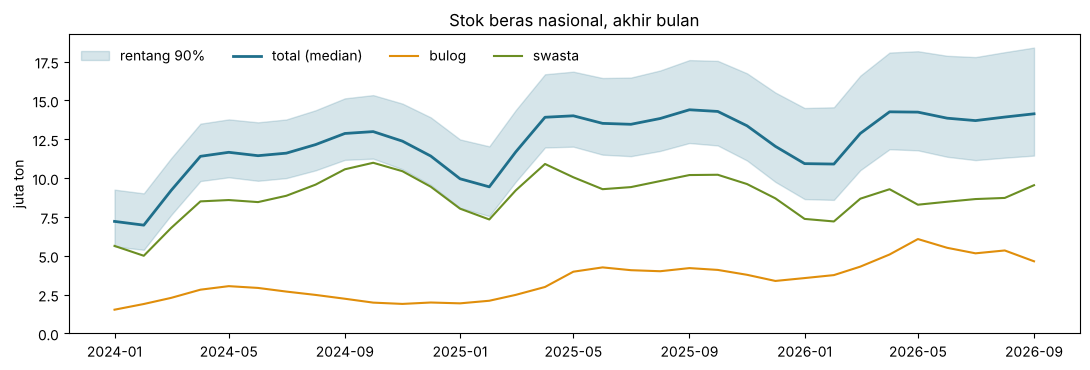

,wilayah,median_juta_ton,p05,p95
1286,Sumatera,3.06,2.22,4.29
1319,Jawa,7.36,5.98,9.28
1352,Bali & Nusa Tenggara,0.89,0.67,1.18
1385,Kalimantan,0.82,0.65,1.07
1418,Sulawesi,1.50,0.92,2.71
1451,Maluku & Papua,0.48,0.33,0.82


In [8]:
fig, ax = plt.subplots(figsize=(11, 3.8))
x = pd.PeriodIndex(nas.index, freq='M').to_timestamp()
ax.fill_between(x, nas.p05, nas.p95, color='#1f6f8b', alpha=.18, label='rentang 90%')
ax.plot(x, nas.median_juta_ton, color='#1f6f8b', lw=2, label='total (median)')
for k, c in [('bulog', '#e08e0b'), ('swasta', '#6b8e23')]:
    s = R[(R.tingkat == 'nasional') & (R.komponen == k)].set_index('periode').median_juta_ton
    ax.plot(x, s.values, color=c, lw=1.5, label=k)
ax.set_ylabel('juta ton'); ax.set_ylim(0); ax.legend(frameon=False, ncol=4); ax.set_title('Stok beras nasional, akhir bulan')
plt.tight_layout(); plt.show()
akhir = AKHIR
pul = R[(R.tingkat == 'pulau') & (R.komponen == 'total') & (R.periode == akhir)][['wilayah', 'median_juta_ton', 'p05', 'p95']]
pul.round(2)

## 5. Validasi survei (prediksi model untuk tiap titik survei)

In [9]:
Xn = idata.posterior['stok'].values.reshape(-1, D['N'], D['T'] + 1).sum(axis=1)
bias = idata.posterior['bias_survei'].values.reshape(-1, 2)
val = []
for t, v, src, dipakai, b in D['surv']:
    j = 0 if src == 'survei_bapanas' else 1
    pred = Xn[:, t] * np.exp(bias[:, j] + 0.05 * np.random.default_rng(1).standard_normal(len(Xn)))
    lo, me, hi = np.percentile(pred / 1e6, [5, 50, 95])
    val.append((b, src, v / 1e6, me, lo, hi, 'ya' if dipakai else 'tidak (disembunyikan)'))
V = pd.DataFrame(val, columns=['periode', 'sumber', 'amatan', 'prediksi_median', 'p05', 'p95', 'dipakai_untuk_fit'])
V.to_csv(os.path.join(HASIL, f'validasi_{LABEL}.csv'), index=False)
V.round(2)

,periode,sumber,amatan,prediksi_median,p05,p95,dipakai_untuk_fit
0,2022-06,survei_bps_scbn,9.71,9.73,8.70,10.93,ya
1,2022-12,survei_bapanas,4.06,4.11,3.67,4.60,ya
2,2023-12,survei_bapanas,4.13,4.19,3.73,4.69,ya
